# Predicting power plant output from ambient conditions

This is a regression problem I liked because the physics is intuitive. A combined cycle power plant's
electrical output changes with the weather. When the intake air is hot and thin the turbine produces
less, when it is cool and dense it produces more. The question here is how accurately you can predict the
net hourly output from four ambient readings alone.

The dataset is the UCI Combined Cycle Power Plant set, 9,568 hourly records taken over six years while the
plant ran at full load. Four inputs:

- `AT` ambient temperature (degrees C)
- `V` exhaust vacuum (cm Hg)
- `AP` ambient pressure (mbar)
- `RH` relative humidity (%)

and the target `PE`, net hourly electrical output in MW.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("data/ccpp.csv")
print(df.shape)
df.describe().round(2)

(9568, 5)


,AT,V,AP,RH,PE
count,9568.00,9568.00,9568.00,9568.00,9568.00
mean,19.65,54.31,1013.26,73.31,454.37
std,7.45,12.71,5.94,14.60,17.07
min,1.81,25.36,992.89,25.56,420.26
25%,13.51,41.74,1009.10,63.33,439.75
50%,20.34,52.08,1012.94,74.97,451.55
75%,25.72,66.54,1017.26,84.83,468.43
max,37.11,81.56,1033.30,100.16,495.76


## What actually moves the output

Before modelling I wanted to see which inputs matter and how. My expectation from the physics was that
temperature would dominate and would be negative, hotter air is less dense, so the turbine has less mass
flow to work with.

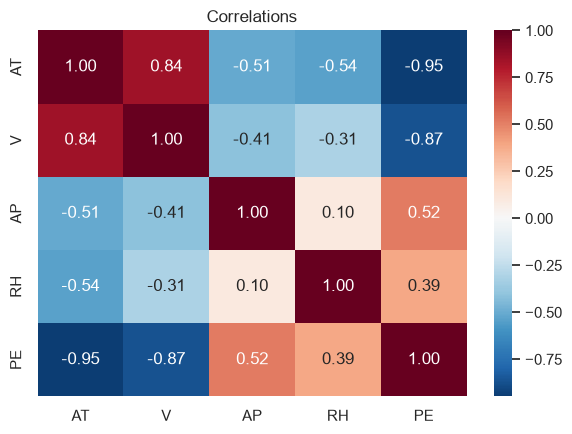

In [2]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(6,4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlations")
plt.tight_layout(); plt.savefig("figures/correlations.png", dpi=110); plt.show()

Temperature is the big one, a strong negative correlation with output, and exhaust vacuum is close
behind (the two are themselves related). Pressure and humidity matter far less. The temperature
relationship is worth looking at directly.

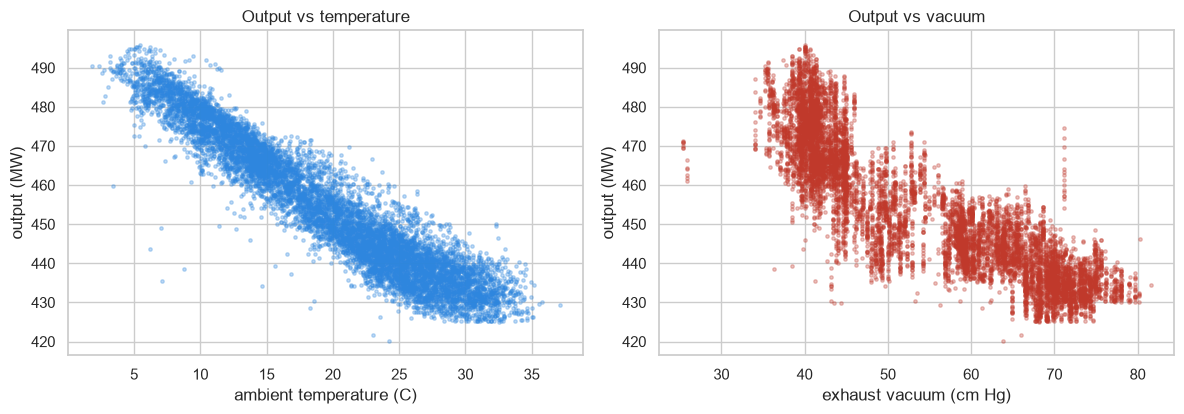

In [3]:
fig, axes = plt.subplots(1,2, figsize=(12,4.3))
axes[0].scatter(df["AT"], df["PE"], s=6, alpha=0.3, color="#2e86de")
axes[0].set_xlabel("ambient temperature (C)"); axes[0].set_ylabel("output (MW)")
axes[0].set_title("Output vs temperature")
axes[1].scatter(df["V"], df["PE"], s=6, alpha=0.3, color="#c0392b")
axes[1].set_xlabel("exhaust vacuum (cm Hg)"); axes[1].set_ylabel("output (MW)")
axes[1].set_title("Output vs vacuum")
plt.tight_layout(); plt.savefig("figures/scatter.png", dpi=110); plt.show()

The temperature relationship is almost a clean straight line with a bit of curvature at the ends, so
a plain linear model should already do well here, and a tree model should pick up the small amount of
curvature on top. Let me check that.

## Modelling

Straightforward setup: an 80/20 train/test split, scale the features for the linear model, and compare a
linear regression baseline against a random forest and a gradient boosting model. For regression I am
reporting RMSE and MAE (both in MW, so they are readable as "how many MW off on average") and R².

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

X = df[["AT","V","AP","RH"]]
y = df["PE"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train", X_train.shape, "test", X_test.shape)

def report(name, y_true, y_pred):
    rmse = root_mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:20s} RMSE={rmse:6.3f}  MAE={mae:6.3f}  R2={r2:.4f}")
    return {"model": name, "rmse": round(float(rmse),3), "mae": round(float(mae),3), "r2": round(float(r2),4)}

train (7654, 4) test (1914, 4)


In [5]:
rows = []

# linear baseline (scaled)
scaler = StandardScaler()
Xtr_s = scaler.fit_transform(X_train); Xte_s = scaler.transform(X_test)
lin = LinearRegression().fit(Xtr_s, y_train)
rows.append(report("linear regression", y_test, lin.predict(Xte_s)))

# random forest
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train)
pred_rf = rf.predict(X_test)
rows.append(report("random forest", y_test, pred_rf))

# gradient boosting
gb = GradientBoostingRegressor(random_state=42).fit(X_train, y_train)
rows.append(report("gradient boosting", y_test, gb.predict(X_test)))

linear regression    RMSE= 4.503  MAE= 3.596  R2=0.9301


random forest        RMSE= 3.229  MAE= 2.313  R2=0.9640


gradient boosting    RMSE= 3.829  MAE= 2.949  R2=0.9495


All three do well, which is no surprise given how clean the temperature relationship is. The tree
models edge ahead of the linear one by picking up the curvature. The best model lands within a few MW on
an output that ranges from about 420 to 496 MW, so the error is around 1% of the reading.

The two plots below are the ones I actually trust for a regression model: predicted against actual (points
should sit on the diagonal) and the residuals (should be a shapeless cloud around zero, with no pattern
left over).

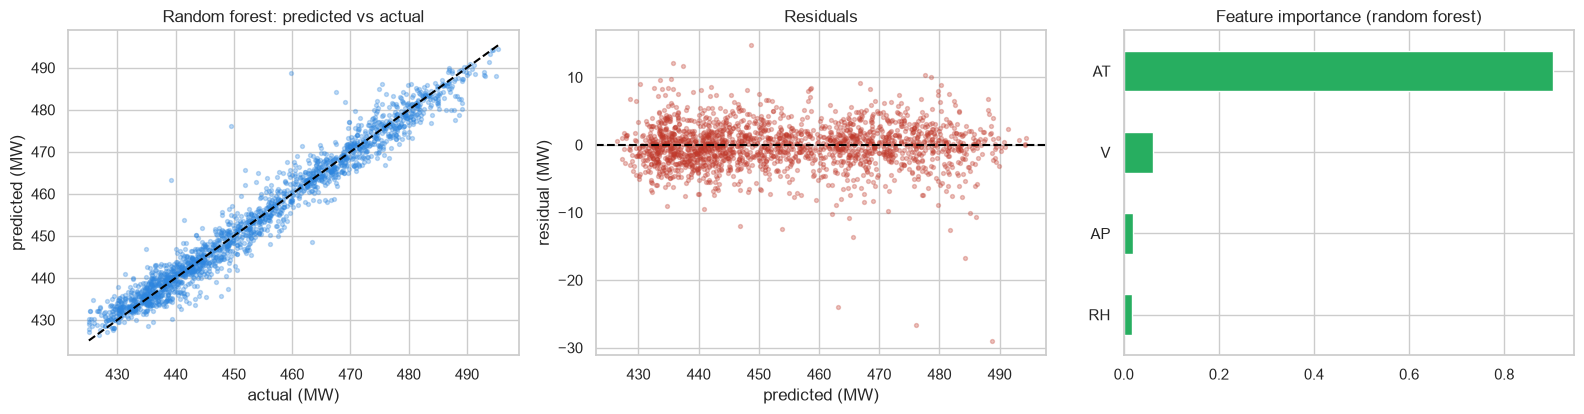

AT    0.901686
V     0.061624
AP    0.018554
RH    0.018135
dtype: float64

In [6]:
fig, axes = plt.subplots(1,3, figsize=(16,4.3))

axes[0].scatter(y_test, pred_rf, s=8, alpha=0.3, color="#2e86de")
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "--", color="black")
axes[0].set_xlabel("actual (MW)"); axes[0].set_ylabel("predicted (MW)")
axes[0].set_title("Random forest: predicted vs actual")

resid = y_test - pred_rf
axes[1].scatter(pred_rf, resid, s=8, alpha=0.3, color="#c0392b")
axes[1].axhline(0, ls="--", color="black")
axes[1].set_xlabel("predicted (MW)"); axes[1].set_ylabel("residual (MW)")
axes[1].set_title("Residuals")

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", ax=axes[2], color="#27ae60")
axes[2].set_title("Feature importance (random forest)")
plt.tight_layout(); plt.savefig("figures/rf_results.png", dpi=110); plt.show()
imp.sort_values(ascending=False)

The predicted-versus-actual points sit tight on the diagonal and the residuals are a flat band around
zero with no obvious shape, which is what you want, it means the model is not systematically missing
anything. Temperature and vacuum carry almost all the predictive weight, matching the correlation view
from the start.

## Takeaways

- Output is highly predictable from ambient conditions alone, the best model reaches an R2 around 0.97
  with an average error of roughly 1% of the reading.
- Temperature is by far the strongest driver, and it is negative, which is exactly what the
  air-density physics predicts. It is nice when the model agrees with the mechanism.
- Tree models beat the linear baseline, but only slightly, because the main relationship really is close
  to linear. This is a good reminder not to reach for a complex model when a simple one is already
  explaining most of the variance.

## Limitations

The plant here is always at full load, so this does not say anything about part-load behaviour. And six
years of one plant will not transfer directly to a different plant with different equipment, the model
would need retraining. For deployment I would also want to watch for sensor drift over time rather than
assuming the calibration from years ago still holds.

In [7]:
import json
summary = {"n_rows": int(len(df)), "models": rows,
           "best": min(rows, key=lambda r: r["rmse"])}
json.dump(summary, open("results.json","w"), indent=2)
print(json.dumps(summary, indent=2))

{
  "n_rows": 9568,
  "models": [
    {
      "model": "linear regression",
      "rmse": 4.503,
      "mae": 3.596,
      "r2": 0.9301
    },
    {
      "model": "random forest",
      "rmse": 3.229,
      "mae": 2.313,
      "r2": 0.964
    },
    {
      "model": "gradient boosting",
      "rmse": 3.829,
      "mae": 2.949,
      "r2": 0.9495
    }
  ],
  "best": {
    "model": "random forest",
    "rmse": 3.229,
    "mae": 2.313,
    "r2": 0.964
  }
}
